# 07 XGBoost on the G0–G3 feature sets

This notebook tunes and validates xgboost on the four cumulative feature sets built in
`02_feature_engineering.ipynb`: G0 raw columns (197) → G1 + row-level features (224) → G2 + card and device
history (234) → G3 + customer history (252). All six model notebooks (04 to 09) follow the same steps and call the
same code in `src/`, so their results can be compared directly in `10_model_comparison.ipynb`.

- **Data:** `data/processed/features_v2.parquet` (build it with `02_feature_engineering.ipynb`). `src.feature_sets`
  drops the test block before anything else sees it, so this notebook never touches it.
- **Splits:** `src/split.py`. Training block = the first 472,432 rows by time; validation = the next 59,054.
- **Every fit** appends one row to `results/log.csv`. Rerunning the notebook skips anything already logged, so it
  can be stopped and restarted. Validation scores are saved to `results/preds/` (not in git) for the comparison
  notebook and a possible ensemble.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Import the model library before anything else: on macOS some model libraries clash with PyTorch's
# threading library if PyTorch is loaded first (see tests/conftest.py).
from src.models import xgb as model

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sklearn.metrics import precision_recall_curve

from src import data, experiment, feature_sets as fs, importance, segments
from src.metrics import top_rows

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

## 1. Settings

- `FEATURE_SETS`: the sets to validate on.
- `TUNE_ON`: `"G3"` tunes once, on the full set, and validates those settings on every set, so the sets are
  compared with the model held fixed. `None` tunes every set separately (four times the tuning cost).
- `GRID`: the settings tried during tuning, defined in the model's file in `src/models/` (logistic regression 11,
  random forest 12, MLP 16, LightGBM, XGBoost and CatBoost 20 each, so every model gets a comparable search). For a quick trial, use e.g. `model.GRID[:2]`, but log such a trial to a
  separate file (`LOG_PATH`) so it doesn't mix with the real runs.
- `SEEDS`: the validation seeds (0, 1, 2 for the group's results).
- `SAVE_OOF`: also save the time-CV fold scores of the chosen settings (4 extra fits per set, each refit as in section 4), needed to train a
  stacking model later.
- `IMPORTANCE_SET`, `IMPORTANCE_ROWS`: the feature set and the number of validation rows used for feature importance
  (section 6). More rows give steadier numbers but take longer.

In [2]:
FEATURE_SETS = ["G0", "G1", "G2", "G3"]
TUNE_ON = "G3"
GRID = model.GRID
SEEDS = [0, 1, 2]
SAVE_OOF = True
LOG_PATH = experiment.LOG_PATH          # results/log.csv
PREDS_DIR = experiment.PREDS_DIR        # results/preds/
MODELS_DIR = experiment.MODELS_DIR      # results/models/ (fitted models, reused by section 6)
IMPORTANCE_SET = FEATURE_SETS[-1]       # G3 by default: all features
IMPORTANCE_ROWS = 20_000
IMPORTANCE_DIR = ROOT / "results" / "importance"

print(f"{model.NAME}: {len(GRID)} settings to tune on {TUNE_ON or 'every set'}, seeds {SEEDS}")
print("defaults:", model.DEFAULTS)
pd.DataFrame(GRID)

xgboost: 20 settings to tune on G3, seeds [0, 1, 2]
defaults: {'n_estimators': 3000, 'max_depth': 6, 'learning_rate': 0.05, 'min_child_weight': 1.0, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'scale_pos_weight': 'balanced', 'n_jobs': 6}


,scale_pos_weight,reg_lambda,min_child_weight,max_depth,learning_rate
0,balanced,1.0,5.0,4,0.03
1,balanced,10.0,20.0,4,0.10
2,balanced,1.0,5.0,6,0.10
3,1.0,3.0,5.0,6,0.03
4,1.0,3.0,1.0,8,0.10
5,1.0,3.0,1.0,10,0.10
6,balanced,10.0,1.0,10,0.03
7,1.0,10.0,1.0,6,0.03
8,balanced,3.0,1.0,10,0.10
9,1.0,10.0,20.0,4,0.03


## 2. Data

In [3]:
df, train_idx, val_idx = fs.load_features()
spec = fs.load_spec()
sets = {name: fs.feature_list(name, spec) for name in FEATURE_SETS}
print(f"rows loaded: {len(df):,} (train {len(train_idx):,}, validation {len(val_idx):,}; test block not loaded)")
print({name: len(cols) for name, cols in sets.items()})

rows loaded: 531,486 (train 472,432, validation 59,054; test block not loaded)
{'G0': 197, 'G1': 224, 'G2': 234, 'G3': 252}


## 3. Model input

**Input:** the same `TreePipeline(kind="lgbm")` as LightGBM: missing values stay missing, categories stay pandas
categories with the training levels, and XGBoost splits on them natively (`enable_categorical=True`, histogram
method).

**Model:** `src/models/xgb.py`. Up to 3,000 trees with early stopping after 50 rounds without a better average
precision (the same measure as `src/metrics.py`), keeping the best round. "balanced" class weight means negatives /
positives of the training part. Each tree uses a random 80% of the rows and 80% of the columns, the same for all three boosting models
(LightGBM, XGBoost, CatBoost), so their differences come from the algorithms; different seeds therefore give
slightly different models. The settings grid is a fixed random sample of 20
combinations of depth, learning rate, minimum child weight, L2 regularisation on the leaf weights (`reg_lambda`
{1, 3, 10}, the same values as LightGBM and CatBoost) and class weight.

In [4]:
def make_pipeline(columns):
    return data.TreePipeline("lgbm", columns=columns)

## 4. Tune and validate

1. **Tune** with time CV inside the training block (seed 0): the block is cut into 30-day bins, and fold k trains on
   bins 0 to k−1 and scores bin k, so every fold scores months the model hasn't seen (4 folds). The settings with
   the highest mean average precision (PR-AUC) are chosen.
2. **Validate:** refit the chosen settings on the whole training block with each seed and score the validation
   block. The decision threshold (best F1) is picked on the validation block and stored in the log for the final
   test scoring.

**Early stopping never sees the scored rows, and the scored model trains on every training row.**
- *Tuning:* in each fold, the last 10% (by time) of the training part is held out and used only to decide when to
  stop; the model trains on the rest and the fold is scored untouched. Every setting loses the same rows, so the
  comparison between settings stays fair.
- *Validation (and the saved fold scores):* two fits. The first trains on the first 90% and finds the stopping
  point on the last 10% (number of trees); the second refits on the whole training part with that stopping point and no
  early stopping, so the most recent rows (the ones closest to the scored period) still reach the scored model.
  The validation block is used in neither fit.

So this model is compared with logistic regression and random forest on the same footing: all of them are scored
after training on the whole training block.

In [5]:
chosen = experiment.tune_and_validate(model, make_pipeline, df, train_idx, val_idx, sets, GRID,
                                      tune_on=TUNE_ON, seeds=SEEDS, log_path=LOG_PATH,
                                      preds_dir=PREDS_DIR, save_oof=SAVE_OOF)
chosen


xgboost/G3: tuning 20 settings with time CV (seed 0)


fold 1 {'scale_pos_weight': 'balanced', 'reg_lambda': 1.0, 'min_child_weight': 5.0, 'max_depth': 4, 'learning_rate': 0.03} pr_auc=0.4507 (9s)


fold 1 {'scale_pos_weight': 'balanced', 'reg_lambda': 10.0, 'min_child_weight': 20.0, 'max_depth': 4, 'learning_rate': 0.1} pr_auc=0.4671 (10s)


fold 1 {'scale_pos_weight': 'balanced', 'reg_lambda': 1.0, 'min_child_weight': 5.0, 'max_depth': 6, 'learning_rate': 0.1} pr_auc=0.4995 (18s)


fold 1 {'scale_pos_weight': 1.0, 'reg_lambda': 3.0, 'min_child_weight': 5.0, 'max_depth': 6, 'learning_rate': 0.03} pr_auc=0.5434 (19s)


fold 1 {'scale_pos_weight': 1.0, 'reg_lambda': 3.0, 'min_child_weight': 1.0, 'max_depth': 8, 'learning_rate': 0.1} pr_auc=0.5246 (13s)


... (89 outputs left out)

xgboost/G3 seed 1: val pr_auc=0.6434 auroc=0.9244 (432s)


xgboost/G3 seed 2: val pr_auc=0.6466 auroc=0.9245 (461s)


xgboost_G3_oof_seed0.parquet: saved under an older early-stopping setup, recomputing


{'G0': {'learning_rate': 0.03,
  'max_depth': 10,
  'min_child_weight': 1.0,
  'reg_lambda': 10.0,
  'scale_pos_weight': 'balanced'},
 'G1': {'learning_rate': 0.03,
  'max_depth': 10,
  'min_child_weight': 1.0,
  'reg_lambda': 10.0,
  'scale_pos_weight': 'balanced'},
 'G2': {'learning_rate': 0.03,
  'max_depth': 10,
  'min_child_weight': 1.0,
  'reg_lambda': 10.0,
  'scale_pos_weight': 'balanced'},
 'G3': {'learning_rate': 0.03,
  'max_depth': 10,
  'min_child_weight': 1.0,
  'reg_lambda': 10.0,
  'scale_pos_weight': 'balanced'}}

## 5. Results

All numbers below are read back from `results/log.csv` (and, for 5.4, the saved validation scores). Precision in
the top 1% is derived from the logged recall in the top 1% (precision = recall × fraud rows ÷ rows flagged), so it
ranks models exactly as recall does but reads more easily: recall in the top 1% is capped well below 1, because the
top 1% of rows holds fewer rows than there are fraud cases.

### 5.1 Tuning
Means over the 4 time-CV folds for the 5 best settings on each tuned set; `chosen` marks the settings validated below.

In [6]:
sizes = experiment.block_sizes(df, train_idx, val_idx)
cv, val = experiment.run_summary(model.NAME, FEATURE_SETS, LOG_PATH, sizes=sizes)
chosen_key = {name: json.dumps(p, sort_keys=True) for name, p in chosen.items()}
cv["chosen"] = [chosen_key.get(r.feature_set) == r.settings for r in cv.itertuples()]
display(cv.groupby("feature_set").head(5).round(4))

,feature_set,settings,cv_pr_auc,cv_std,cv_auroc,cv_recall_top1pct,cv_precision_top1pct,folds,chosen
0,G3,"{""learning_rate"": 0.03, ""max_depth"": 10, ""min_child_weight"": 1.0, ""reg_lambda"": 10.0, ""scale_pos_weight"": ""balanced""}",0.5819,0.0297,0.8953,0.2451,0.9433,4,True
1,G3,"{""learning_rate"": 0.03, ""max_depth"": 10, ""min_child_weight"": 1.0, ""reg_lambda"": 1.0, ""scale_pos_weight"": 1.0}",0.5792,0.0291,0.8988,0.2438,0.9388,4,False
2,G3,"{""learning_rate"": 0.1, ""max_depth"": 10, ""min_child_weight"": 1.0, ""reg_lambda"": 3.0, ""scale_pos_weight"": ""balanced""}",0.5787,0.0313,0.8910,0.2446,0.9416,4,False
3,G3,"{""learning_rate"": 0.03, ""max_depth"": 8, ""min_child_weight"": 1.0, ""reg_lambda"": 10.0, ""scale_pos_weight"": 1.0}",0.5728,0.0319,0.8955,0.2424,0.9331,4,False
4,G3,"{""learning_rate"": 0.1, ""max_depth"": 10, ""min_child_weight"": 1.0, ""reg_lambda"": 1.0, ""scale_pos_weight"": ""balanced""}",0.5727,0.0222,0.8884,0.2446,0.9414,4,False


### 5.2 Validation block, chosen settings
Mean ± sample sd over the seeds. Precision and recall "at threshold" use the F1-best threshold picked on the validation
block itself, so they are slightly optimistic; the test block is scored once with the stored threshold after the freeze.

In [7]:
val = val[[chosen_key.get(r.feature_set) == r.settings for r in val.itertuples()]]
val = val.set_index("feature_set").reindex(FEATURE_SETS)
labels = {"pr_auc": "PR-AUC", "auroc": "AUROC", "recall_top1pct": "recall top 1%",
          "precision_top1pct": "precision top 1%", "precision": "precision at threshold",
          "recall": "recall at threshold"}
table = pd.DataFrame({label: val[f"{m}_mean"].map("{:.4f}".format) + " ± " + val[f"{m}_std"].map("{:.4f}".format)
                      for m, label in labels.items()})
table["threshold"] = val["threshold_mean"].round(4)
table["seeds"] = val["seeds"]
n_val, fraud_val = sizes["val"]
print(f"Validation block: {fraud_val:,} fraud in {n_val:,} rows. The top 1% is {top_rows(n_val):,} rows, "
      f"so recall in the top 1% is at most {top_rows(n_val) / fraud_val:.3f}.")
display(table)

Validation block: 1,851 fraud in 59,054 rows. The top 1% is 591 rows, so recall in the top 1% is at most 0.319.


,PR-AUC,AUROC,recall top 1%,precision top 1%,precision at threshold,recall at threshold,threshold,seeds
feature_set,,,,,,,,
G0,0.6057 ± 0.0302,0.9174 ± 0.0072,0.2932 ± 0.0064,0.9182 ± 0.0200,0.7105 ± 0.0207,0.5134 ± 0.0399,0.5062,3
G1,0.6495 ± 0.0025,0.9246 ± 0.0013,0.3022 ± 0.0003,0.9464 ± 0.0010,0.7198 ± 0.0067,0.5601 ± 0.0017,0.3900,3
G2,0.6449 ± 0.0023,0.9239 ± 0.0009,0.3002 ± 0.0006,0.9402 ± 0.0020,0.7367 ± 0.0039,0.5527 ± 0.0025,0.3950,3
G3,0.6434 ± 0.0032,0.9242 ± 0.0004,0.2995 ± 0.0003,0.9380 ± 0.0010,0.7263 ± 0.0408,0.5487 ± 0.0242,0.3853,3


**Precision–recall curves** on the validation block (seed 0), one per feature set. PR-AUC is the area under each
curve; the dashed line is a model with no skill (precision = fraud rate).

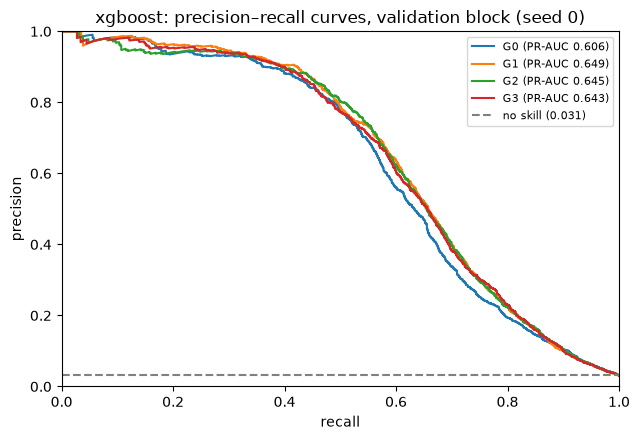

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name in FEATURE_SETS:
    path = PREDS_DIR / f"{model.NAME}_{name}_val_seed0.parquet"
    if path.exists():
        p = pd.read_parquet(path)
        precision, recall, _ = precision_recall_curve(p["isFraud"], p["score"])
        ax.plot(recall, precision, label=f"{name} (PR-AUC {val.loc[name, 'pr_auc_mean']:.3f})", lw=1.5)
ax.axhline(fraud_val / n_val, ls="--", color="grey", label=f"no skill ({fraud_val / n_val:.3f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"{model.NAME}: precision–recall curves, validation block (seed 0)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 5.3 What each feature group adds
Change in mean validation PR-AUC from one set to the next (same settings on every set when `TUNE_ON` is a set name).

,G0 → G1,G1 → G2,G2 → G3,G0 → G3
change in PR-AUC,0.0437,-0.0046,-0.0014,0.0377


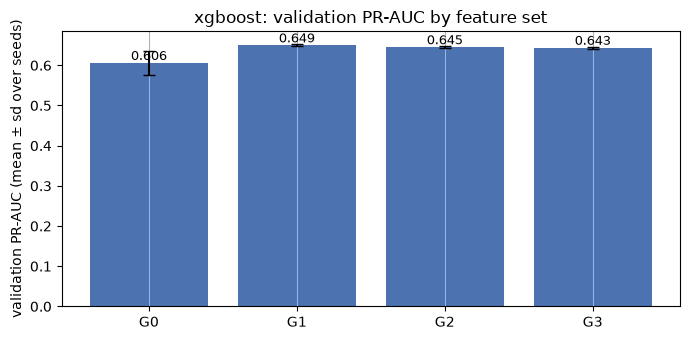

In [9]:
pr = val["pr_auc_mean"]
gains = {f"{a} → {b}": pr[b] - pr[a] for a, b in zip(FEATURE_SETS[:-1], FEATURE_SETS[1:])}
if len(FEATURE_SETS) > 2:
    gains[f"{FEATURE_SETS[0]} → {FEATURE_SETS[-1]}"] = pr[FEATURE_SETS[-1]] - pr[FEATURE_SETS[0]]
display(pd.DataFrame([gains], index=["change in PR-AUC"]).round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(val.index, val["pr_auc_mean"], yerr=val["pr_auc_std"].fillna(0), color="#4C72B0", capsize=4)
for x, y in zip(val.index, val["pr_auc_mean"]):
    ax.text(x, y, f"{y:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("validation PR-AUC (mean ± sd over seeds)")
ax.set_title(f"{model.NAME}: validation PR-AUC by feature set")
ax.grid(axis="x")
fig.tight_layout()
plt.show()

### 5.4 Known vs unknown customers
A validation row is **known** if its `uid` appears in the training block (`src/segments.py`). PR-AUC is the mean over
the seeds, with a 95% bootstrap interval over rows (`N_BOOT` resamples). `10_model_comparison.ipynb` shows the same
split for all models side by side.

In [10]:
N_BOOT = 200
known = segments.known_uid(df["uid"].iloc[val_idx], set(df["uid"].iloc[train_idx]))
rows = []
for name in FEATURE_SETS:
    paths = [PREDS_DIR / f"{model.NAME}_{name}_val_seed{s}.parquet" for s in SEEDS]
    if not all(p.exists() for p in paths):
        print(f"{name}: validation scores not saved for every seed, skipped")
        continue
    preds = [pd.read_parquet(p) for p in paths]
    if not all((p["TransactionID"].to_numpy() == df["TransactionID"].iloc[val_idx].to_numpy()).all() for p in preds):
        raise ValueError(f"{name}: saved scores don't match the validation rows")
    t = segments.segment_pr_auc(preds[0]["isFraud"].to_numpy(), [p["score"].to_numpy() for p in preds], known,
                                n_boot=N_BOOT)
    rows.append(t.assign(feature_set=name))
if rows:
    seg = pd.concat(rows, ignore_index=True)
    display(seg.groupby("segment")[["rows", "fraud"]].first())
    seg["PR-AUC [95% interval]"] = (seg["pr_auc"].map("{:.4f}".format) + " [" + seg["low"].map("{:.3f}".format)
                                    + ", " + seg["high"].map("{:.3f}".format) + "]")
    display(seg.pivot(index="feature_set", columns="segment", values="PR-AUC [95% interval]").reindex(FEATURE_SETS))

,rows,fraud
segment,,
known,28685,640
unknown,30369,1211


segment,known,unknown
feature_set,,
G0,"0.8040 [0.771, 0.834]","0.5175 [0.492, 0.547]"
G1,"0.8427 [0.811, 0.871]","0.5427 [0.519, 0.575]"
G2,"0.8445 [0.815, 0.872]","0.5348 [0.513, 0.565]"
G3,"0.8414 [0.811, 0.869]","0.5369 [0.515, 0.568]"


### 5.5 How the settings affect performance (RQ4)

Read from the tuning runs already in the log, with no extra training: for each tuned setting and each value it
took, the mean time-CV PR-AUC of the combinations tried with that value (dot), and the best and worst of them
(bar). The star marks the chosen value. This model uses random search (20 combinations), so each value is paired with a different mix of other settings; treat the means as indicative, not as a controlled one-at-a-time sweep. The number of trees (boosting models) or epochs (MLP) is not
a tuned setting: early stopping picks it in every fit.

,setting,value,mean,best,worst,combinations
0,learning_rate,0.03,0.5512,0.5819,0.4840,12
1,learning_rate,0.1,0.5513,0.5787,0.5086,8
2,max_depth,10,0.5737,0.5819,0.5644,6
3,max_depth,4,0.5202,0.5458,0.4840,4
4,max_depth,6,0.5438,0.5614,0.5175,5
5,max_depth,8,0.5567,0.5728,0.5395,5
6,min_child_weight,1.0,0.5708,0.5819,0.5612,9
7,min_child_weight,5.0,0.5379,0.5601,0.4840,6
8,min_child_weight,20.0,0.5321,0.5524,0.5086,5
9,reg_lambda,1.0,0.5459,0.5792,0.4840,7


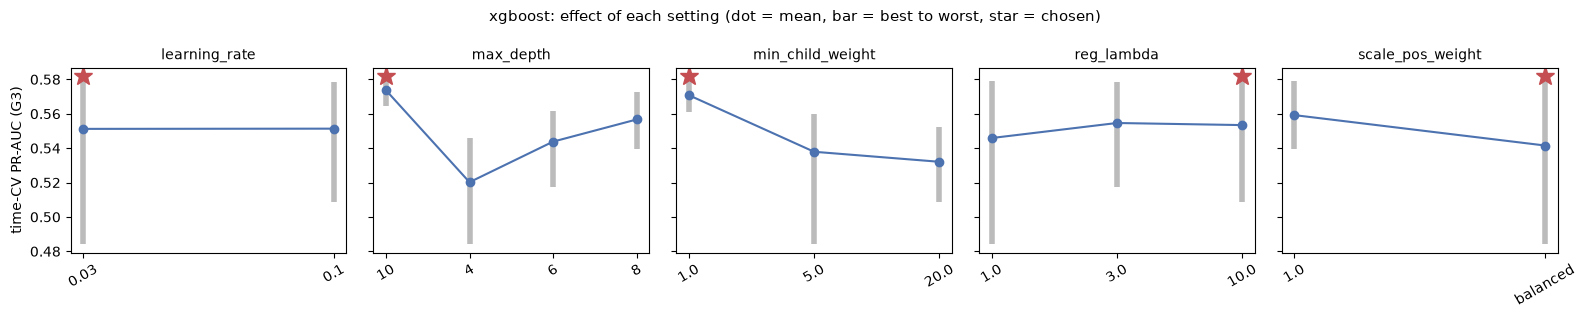

In [11]:
SENS_SET = TUNE_ON or FEATURE_SETS[-1]
sens = experiment.setting_sensitivity(model.NAME, SENS_SET, LOG_PATH)
if sens.empty:
    print("Fewer than two values tried for every setting: nothing to show.")
else:
    display(sens.round(4))
    settings_ = list(dict.fromkeys(sens["setting"]))
    n = len(settings_)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.2), sharey=True, squeeze=False)
    for ax, name in zip(axes[0], settings_):
        part = sens[sens["setting"] == name].reset_index(drop=True)
        x = range(len(part))
        ax.vlines(x, part["worst"], part["best"], color="#BBBBBB", lw=4)
        ax.plot(x, part["mean"], "o-", color="#4C72B0")
        picked = chosen[SENS_SET].get(name)
        for i, v in enumerate(part["value"]):
            if v == picked or (picked is None and v == "none"):
                ax.plot(i, part.loc[i, "best"], "*", ms=14, color="#C44E52")
        ax.set_xticks(list(x), [str(v) for v in part["value"]], rotation=30)
        ax.set_title(name, fontsize=10)
    axes[0][0].set_ylabel(f"time-CV PR-AUC ({SENS_SET})")
    fig.suptitle(f"{model.NAME}: effect of each setting (dot = mean, bar = best to worst, star = chosen)", fontsize=11)
    fig.tight_layout()
    plt.show()

## 6. Feature importance

For the chosen settings on `IMPORTANCE_SET` (G3 by default), refit on the training block exactly as in the seed-0
validation run (cached in `results/models/`, so this runs once), then measure:

- **Permutation importance:** how much validation PR-AUC drops when one input column is shuffled (on
  `IMPORTANCE_ROWS` validation rows). It means the same thing for every model, so it can be compared across notebooks.
- **Built-in importance:** total gain of the splits on each input.

Correlated columns share credit: shuffling one leaves its near-copy in place, so a small drop does not prove a column
is useless. Importances describe what this model relies on, not causes of fraud. The table is also saved to
`results/importance/` for `10_model_comparison.ipynb`.

In [12]:
cols = sets[IMPORTANCE_SET]
fitted, pipe = experiment.fit_final(model, lambda: make_pipeline(cols), df, train_idx, chosen[IMPORTANCE_SET],
                                    IMPORTANCE_SET, seed=0, cache_dir=MODELS_DIR)
X_val = pipe.transform(df.iloc[val_idx])
y_val = df["isFraud"].iloc[val_idx].to_numpy()
group_of = importance.feature_groups(spec)

perm = importance.permutation(fitted, X_val, y_val, cols, n_rows=IMPORTANCE_ROWS, seed=0)
built_in = importance.intrinsic(model, fitted, list(X_val.columns), cols)
imp = perm[["pr_auc_drop"]].assign(group=[group_of.get(c, "?") for c in perm.index])
if built_in is not None:
    imp["built_in"] = built_in
    imp["built_in_share"] = built_in / built_in.sum()
imp = imp.sort_values("pr_auc_drop", ascending=False)
print(f"PR-AUC on the {min(IMPORTANCE_ROWS, len(val_idx)):,} rows used: {perm['base_pr_auc'].iloc[0]:.4f} "
      f"(built-in importance: {model.IMPORTANCE or 'none'})")
IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)
imp.assign(model=model.NAME, feature_set=IMPORTANCE_SET).to_csv(IMPORTANCE_DIR / f"{model.NAME}_{IMPORTANCE_SET}.csv")
display(imp.head(20).round(4))

PR-AUC on the 20,000 rows used: 0.6248 (built-in importance: total gain)


,pr_auc_drop,group,built_in,built_in_share
feature,,,,
C1,0.0710,G0_raw,671054.1875,0.0361
fe_freq_card1,0.0390,G2_card_device_history,497915.0000,0.0268
TransactionAmt,0.0377,G0_raw,437975.8125,0.0236
card1,0.0310,G0_raw,418529.9688,0.0225
fe_D1n,0.0302,G1_row_level,518146.2812,0.0279
addr1,0.0291,G0_raw,348137.1875,0.0187
P_emaildomain,0.0291,G0_raw,798292.8750,0.0430
C13,0.0273,G0_raw,365021.1250,0.0196
card2,0.0259,G0_raw,412662.8750,0.0222


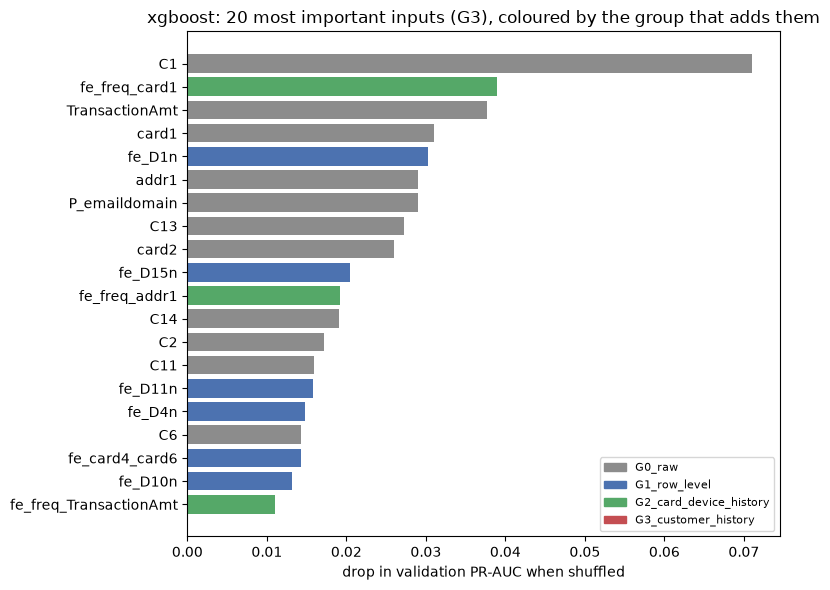

Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):


,sum,count
group,,
G0_raw,0.4515,197
G1_row_level,0.1347,27
G2_card_device_history,0.0751,10
G3_customer_history,0.0171,18


In [13]:
top = imp.head(20).iloc[::-1]
colors = {"G0_raw": "#8C8C8C", "G1_row_level": "#4C72B0", "G2_card_device_history": "#55A868",
          "G3_customer_history": "#C44E52"}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["pr_auc_drop"], color=[colors.get(g, "#999999") for g in top["group"]])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, list(colors), fontsize=8, loc="lower right")
ax.set_xlabel("drop in validation PR-AUC when shuffled")
ax.set_title(f"{model.NAME}: 20 most important inputs ({IMPORTANCE_SET}), coloured by the group that adds them")
fig.tight_layout()
plt.show()

print("Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):")
display(imp.groupby("group")["pr_auc_drop"].agg(["sum", "count"]).sort_values("sum", ascending=False).round(4))

## 7. Findings

Chosen settings (tuned once on G3, held fixed on every set): learning rate 0.03, max depth 10, min_child_weight 1,
reg_lambda 10, balanced class weight. Time-CV PR-AUC 0.5819 ± 0.0297 (table 5.1).

- **Feature sets (5.2, 5.3).** Validation PR-AUC is 0.6057 on G0, 0.6495 on G1, 0.6449 on G2 and 0.6434 on G3
  (AUROC 0.9174 to 0.9246). The row-level features carry all of the gain: G0 → G1 adds 0.0437, while G1 → G2
  (−0.0046) and G2 → G3 (−0.0014) are within the spread between seeds. G1, G2 and G3 are effectively tied. Tuning
  on G3 should if anything favour G3, so the card, device and customer history features add nothing measurable for
  XGBoost. G0 → G3 adds 0.0377 in total.
- **Known vs unknown customers (5.4).** Known customers (640 fraud in 28,685 rows) score far higher than unknown ones
  (1,211 fraud in 30,369 rows): 0.8414 vs 0.5369 on G3. From G0 to G1 known customers gain 0.0387 (0.8040 → 0.8427)
  and unknown ones 0.0252 (0.5175 → 0.5427). The history sets do not add to either group (G3: known 0.8414, unknown
  0.5369), and the bootstrap intervals of G1, G2 and G3 overlap almost completely. The EDA expectation that customer
  history helps mainly known customers is not borne out here: the G1 features already let the model recognise them.
- **Edge of the grid.** Every chosen value except the class weight is at an end of its range: the deepest trees (10),
  the smallest min_child_weight (1), the slower learning rate (0.03) and the strongest L2 penalty (10). Deeper or
  less constrained trees might score higher; the grid was not widened, so this is untested.
- **Tree cap.** No tuning fit reached the 3,000-tree cap (the most was 2,607), but the validation fits train on the
  whole training block, and 6 of the 12 kept a stopping point within 50 trees of the cap (2,977 to 2,998), so they
  were still improving when they stopped. This affects every set (one or two seeds each), so it does not change the
  comparison between sets, but those scores may be slightly low. We keep the cap at 3,000 so all boosting models
  share it, and note this as a limitation.
- **Spread between seeds.** G0 varies far more than the other sets (sd 0.0302 vs 0.0025 to 0.0032): seed 1 stopped at
  769 trees and scored 0.5710, against 0.6251 and 0.6211 for seeds 0 and 2. The seed only changes row and column
  sampling, so on the raw columns alone early stopping can settle on an early, worse peak.
- **Settings that matter (5.5).** Tree size matters most. Mean CV PR-AUC rises from 0.5202 at depth 4 to 0.5737 at
  depth 10, and falls from 0.5708 at min_child_weight 1 to 0.5321 at 20. The learning rate barely moves the mean
  (0.5512 vs 0.5513), since early stopping adjusts the number of trees, and reg_lambda moves it by under 0.01. No
  class weight has the higher mean (0.5592 vs 0.5415 balanced), but the best combination is balanced, and the top
  two settings (0.5819 balanced, 0.5792 unweighted) are within 0.003, so class weighting is not decisive.
- **Inputs that matter (6).** The raw columns dominate: C1 is the most important input by far (PR-AUC drop 0.0710),
  followed by fe_freq_card1 (0.0390), TransactionAmt (0.0377) and card1 (0.0310). Engineered features appear
  throughout the top 20: the normalised D columns fe_D1n (5th), fe_D15n, fe_D11n, fe_D4n and fe_D10n, plus the
  frequency encodings fe_freq_card1 and fe_freq_addr1. By group, the summed drop is 0.4515 for G0 (197 columns),
  0.1347 for G1 (27), 0.0751 for G2 (10) and 0.0171 for G3 (18). The best customer-history feature,
  fe_uid_c13_rel_prior_mean, is only 28th (drop 0.0060). This matches 5.3: the row-level features matter, and the
  customer-history features add little. G2 features rank well individually although G2 adds nothing over G1 in 5.3,
  most likely because they overlap with what G1 and the raw card and address columns already capture.